In [5]:
import xarray as xr
#import rioxarray
import numpy as np
import matplotlib.pyplot as plt
import geopandas
from tqdm import tqdm
from shapely.geometry import box
import fiona
import rasterio
import rasterio.mask
#import cartopy.crs as ccrs
#import cartopy
import pandas as pd
import glob
#import pygeos
geopandas.options.use_pygeos = True

/tmp/ipykernel_54169/2588560377.py:16: UserWarning: pygeos support was removed in 1.0. geopandas.use_pygeos is a no-op and will be removed in geopandas 1.1.
  geopandas.options.use_pygeos = True


In [2]:
# Get CSV files list from a folder
path = '/home/chandra/data/Paper4/'
csv_files = glob.glob(path + "/AREA_IMOVEL.shp")


In [3]:
import pandas as pd
import pathlib

data_dir = '/home/chandra/data/Paper4/SICAR/'
out_dir = '.'

list_files = []
for filename in pathlib.Path(data_dir).glob('**/*.shp'):
    list_files.append(filename)


In [4]:
df = pd.concat(map(geopandas.read_file, list_files), ignore_index=True)

In [6]:
df['Stakeholder_size'] = np.nan
for frame in tqdm(range(len(df))):
    if df['NUM_MODULO'].iloc[frame] <= 4:
        df['Stakeholder_size'].iloc[frame] = 1
    #if (df['NUM_MODULO'].iloc[frame] > 1) & (df['NUM_MODULO'].iloc[frame] <= 4):
    #    df['Stakeholder_size'].iloc[frame] = 2
    if (df['NUM_MODULO'].iloc[frame] > 4) & (df['NUM_MODULO'].iloc[frame] <= 15):
        df['Stakeholder_size'].iloc[frame] = 2
    if df['NUM_MODULO'].iloc[frame] > 15:
        df['Stakeholder_size'].iloc[frame] = 3

  0%|          | 0/6492338 [00:00<?, ?it/s]/tmp/ipykernel_3405969/648122752.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Stakeholder_size'].iloc[frame] = 1
/tmp/ipykernel_3405969/648122752.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Stakeholder_size'].iloc[frame] = 2
/tmp/ipykernel_3405969/648122752.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Stakeholder_size'].iloc[frame] = 3
100%|██████████| 649233

In [7]:
points = df.copy()
# change geometry 
points['geometry'] = df['geometry'].centroid

/tmp/ipykernel_3405969/2853626738.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  points['geometry'] = df['geometry'].centroid


In [9]:
base_shape = geopandas.read_file('/home/chandra/data/Paper4/Output/Base_shapefile_all_SA.shp')

In [11]:
import warnings
warnings.filterwarnings('ignore')
base_shape['SICAR_dominance'] = np.nan
for frame in tqdm(range(len(base_shape))):
    SICAR_clipped = geopandas.clip(points, base_shape.iloc[[frame]])
    a = []
    for i in [1,2,3]:
        a.append(SICAR_clipped.where(SICAR_clipped['Stakeholder_size'] == i).dropna()['NUM_AREA'].sum()/100)
    if np.sum(a) == 0:
        continue
    else:
        base_shape['SICAR_dominance'].iloc[frame] = np.argmax(a)+1

100%|██████████| 8664/8664 [2:14:18<00:00,  1.08it/s]  


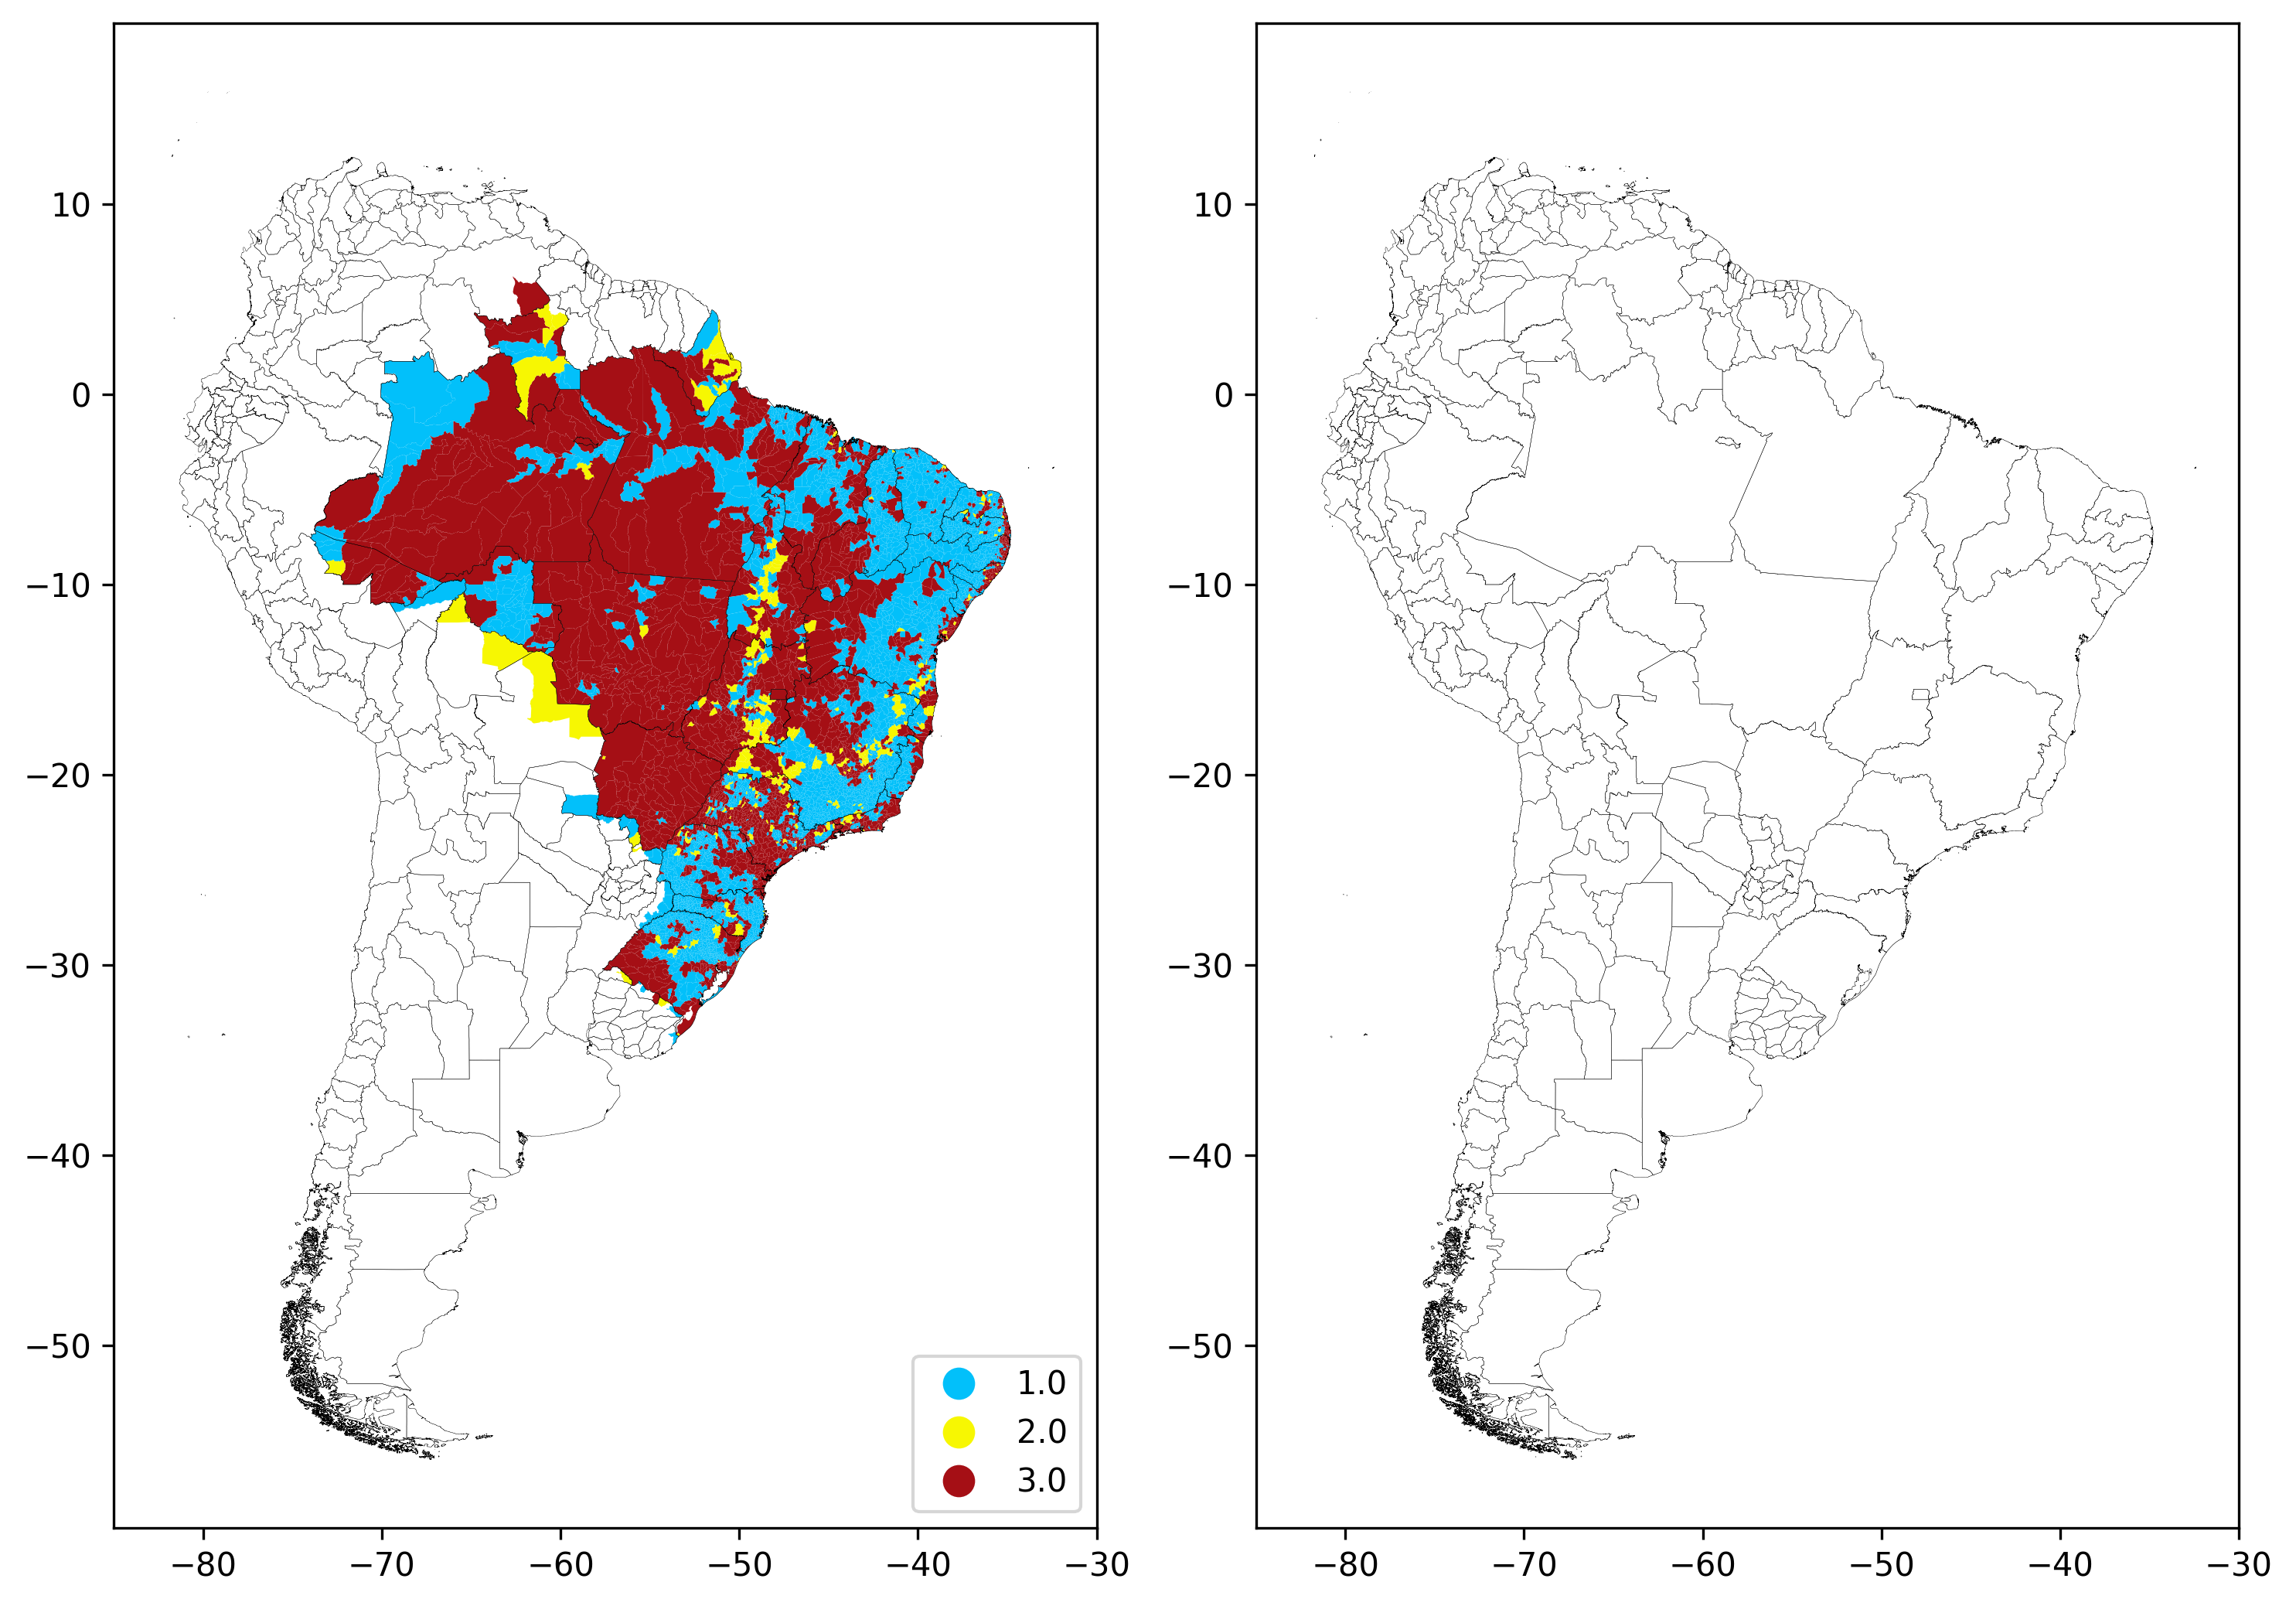

In [15]:
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
cmap = ListedColormap(['#02c0fa','#f7f702',"#a50f15"])
cmap

Municipality_major_SA = geopandas.read_file('/home/chandra/data/Paper4/Data_previous_literature/SA_shape_AB2/AB0-1/SA_level1AB_Merge.shp')
fig, ax = plt.subplots(1,2, figsize=(10,18), dpi = 300)

base_shape.plot(column = 'SICAR_dominance', legend = True, cmap = cmap, ax = ax[0], categorical=True, legend_kwds={'loc': 'lower right'})


Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[0], lw = 0.1)
Municipality_major_SA.plot(column = 'NAME_1', edgecolor = 'k', facecolor = 'None', ax = ax[1], lw = 0.1)

for i in range(2):
    ax[i].set_xlim(-85, -30)
plt.tight_layout()

In [7]:
base_shape.to_file('Private/chandra/data/Paper4/Output/Actor_dominance_SICAR.shp', mode="w")  

NameError: name 'base_shape' is not defined

In [11]:
Municipality = geopandas.read_file('/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.shp')

In [12]:
Municipality[['ID','Name','Dominance','Dominance-']]

,ID,Name,Dominance,Dominance-
0,0,Brazil_PR_Lupionópolis,1,Crop-Small
1,1,Brazil_SP_Águas de Lindóia,2,Crop-Medium
2,2,Brazil_PA_Uruará,3,Crop-Large
3,3,Brazil_RS_São Leopoldo,2,Crop-Medium
4,4,Brazil_SP_Vargem,1,Crop-Small
...,...,...,...,...
6869,8402,Venezuela-Bolívar-Sucre,4,Remote
6870,8427,Venezuela-Delta Amacuro-Antonio Diaz,2,Crop-Medium
6871,8428,Venezuela-Delta Amacuro-Casacoima,1,Crop-Small
6872,8429,Venezuela-Delta Amacuro-Pedernales,2,Crop-Medium


In [14]:
SICAR = geopandas.read_file('/cfs/klemming/projects/supr/chandra/data/Paper4/Output/Actor_dominance_SICAR.shp')

In [15]:
SICAR = pd.merge(SICAR, Municipality[['ID','Name','Dominance','Dominance-']],#, 'AreaT']], 
         on="ID", how="left")

In [16]:
SICAR = SICAR.dropna()

In [17]:
SICAR['Dominance-'].unique()

array(['Crop-Small', 'Crop-Medium', 'Crop-Large', 'Remote'], dtype=object)

In [18]:
SICAR['Dominance-'] = SICAR['Dominance-'].replace(to_replace='Crop-Small', value = 1)
SICAR['Dominance-'] = SICAR['Dominance-'].replace(to_replace='Crop-Medium', value = 2)
SICAR['Dominance-'] = SICAR['Dominance-'].replace(to_replace='Crop-Large', value = 3)
SICAR['Dominance-'] = SICAR['Dominance-'].replace(to_replace='Remote', value = 4)

/tmp/ipykernel_54169/1789100072.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  SICAR['Dominance-'] = SICAR['Dominance-'].replace(to_replace='Remote', value = 4)


In [19]:
SICAR

,Name_x,ID,SICAR_domi,geometry,Name_y,Dominance,Dominance-
0,Brazil_PR_Lupionópolis,0,3.0,"POLYGON Z ((-51.63021 -22.66372 0, -51.63011 -...",Brazil_PR_Lupionópolis,1.0,1
1,Brazil_SP_Águas de Lindóia,1,1.0,"POLYGON Z ((-46.61019 -22.43936 0, -46.60345 -...",Brazil_SP_Águas de Lindóia,2.0,2
2,Brazil_PA_Uruará,2,1.0,"POLYGON Z ((-53.85954 -2.8875 0, -53.85825 -2....",Brazil_PA_Uruará,3.0,3
3,Brazil_RS_São Leopoldo,3,3.0,"POLYGON Z ((-51.17861 -29.69309 0, -51.17045 -...",Brazil_RS_São Leopoldo,2.0,2
4,Brazil_SP_Vargem,4,1.0,"POLYGON Z ((-46.39678 -22.81069 0, -46.39477 -...",Brazil_SP_Vargem,1.0,1
...,...,...,...,...,...,...,...
8253,Uruguay-Rivera-n.a12,8253,1.0,"POLYGON Z ((-55.48143 -30.95158 0, -55.47681 -...",Uruguay-Rivera-n.a12,1.0,1
8256,Uruguay-Rivera-n.a17,8256,1.0,"POLYGON Z ((-55.16158 -31.29091 0, -55.16765 -...",Uruguay-Rivera-n.a17,3.0,3
8260,Uruguay-Rivera-n.a28,8260,3.0,"POLYGON Z ((-54.57891 -32.0343 0, -54.58088 -3...",Uruguay-Rivera-n.a28,3.0,3
8263,Uruguay-Rocha-n.a289,8263,1.0,"MULTIPOLYGON Z (((-53.52819 -33.96875 0, -53.5...",Uruguay-Rocha-n.a289,3.0,3


In [20]:
SICAR.where(SICAR['Dominance'] == 3).dropna()[['SICAR_domi', 'Dominance']].corr()

,SICAR_domi,Dominance
SICAR_domi,1.0,NaN
Dominance,NaN,NaN


In [21]:
SICAR = SICAR.where(SICAR['Dominance'] <= 3).dropna()

In [22]:
SICAR[['SICAR_domi','Dominance']].corr()

,SICAR_domi,Dominance
SICAR_domi,1.000000,0.109793
Dominance,0.109793,1.000000


In [23]:
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import cartopy as cart

cmap = ListedColormap(['#2B8CBE','#FFFF99',"#FB6A4A"])
cmap

fig, ax = plt.subplots(1,3, figsize=(10,18), dpi = 300)
base_shape = geopandas.read_file('/home/chandra/data/Paper4/Output/Base_shapefile_all_SA.shp')

SICAR.plot(column = 'SICAR_domi', cmap = cmap, ax = ax[0], lw = 0.1, legend = False, categorical=True, legend_kwds={'loc': 'lower right'})
SICAR.plot(column = 'Dominance-', cmap = cmap, ax = ax[1], lw = 0.1, legend = False, categorical=True, legend_kwds={'loc': 'lower right'})
SICAR.plot(column = 'Dominance', cmap = cmap, ax = ax[2], lw = 0.1, legend = False, categorical=True, legend_kwds={'loc': 'lower right'})

for i in range(3):
    base_shape.plot(column = 'ID', edgecolor = 'k', facecolor = 'None', ax = ax[i], lw = 0.03)
    ax[i].set_xlim(-85, -30)
    ax[i].set_ylim(-35, 15)
    ax[i].axis('off')
    base_shape.plot(color = '#DADADA', edgecolor = 'None', facecolor = 'None', lw = 0.01, ax = ax[i], zorder = -100)

ax[0].set_title('from CAR database', fontsize = '12')
ax[1].set_title('(this study) \nCropland-classified \nlandholders dominance', fontsize = '12')
ax[2].set_title('(this study) \nFinal-landholders dominance', fontsize = '12')

plt.tight_layout()

ModuleNotFoundError: No module named 'cartopy'

In [24]:
SICAR

,Name_x,ID,SICAR_domi,geometry,Name_y,Dominance,Dominance-
0,Brazil_PR_Lupionópolis,0.0,3.0,"POLYGON Z ((-51.63021 -22.66372 0, -51.63011 -...",Brazil_PR_Lupionópolis,1.0,1.0
1,Brazil_SP_Águas de Lindóia,1.0,1.0,"POLYGON Z ((-46.61019 -22.43936 0, -46.60345 -...",Brazil_SP_Águas de Lindóia,2.0,2.0
2,Brazil_PA_Uruará,2.0,1.0,"POLYGON Z ((-53.85954 -2.8875 0, -53.85825 -2....",Brazil_PA_Uruará,3.0,3.0
3,Brazil_RS_São Leopoldo,3.0,3.0,"POLYGON Z ((-51.17861 -29.69309 0, -51.17045 -...",Brazil_RS_São Leopoldo,2.0,2.0
4,Brazil_SP_Vargem,4.0,1.0,"POLYGON Z ((-46.39678 -22.81069 0, -46.39477 -...",Brazil_SP_Vargem,1.0,1.0
...,...,...,...,...,...,...,...
8253,Uruguay-Rivera-n.a12,8253.0,1.0,"POLYGON Z ((-55.48143 -30.95158 0, -55.47681 -...",Uruguay-Rivera-n.a12,1.0,1.0
8256,Uruguay-Rivera-n.a17,8256.0,1.0,"POLYGON Z ((-55.16158 -31.29091 0, -55.16765 -...",Uruguay-Rivera-n.a17,3.0,3.0
8260,Uruguay-Rivera-n.a28,8260.0,3.0,"POLYGON Z ((-54.57891 -32.0343 0, -54.58088 -3...",Uruguay-Rivera-n.a28,3.0,3.0
8263,Uruguay-Rocha-n.a289,8263.0,1.0,"MULTIPOLYGON Z (((-53.52819 -33.96875 0, -53.5...",Uruguay-Rocha-n.a289,3.0,3.0


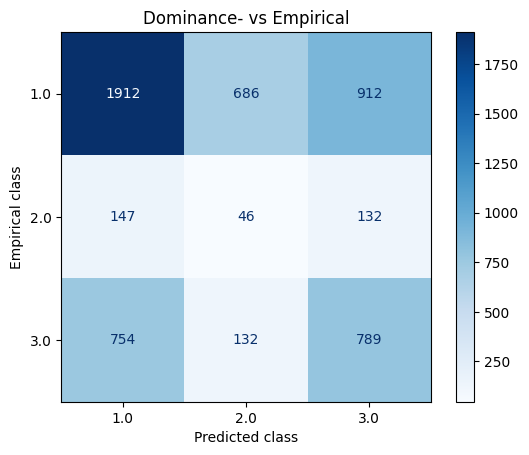


--- Dominance- ---
N: 5510
Accuracy: 0.4985480943738657
Balanced accuracy: 0.3857708607957364
F1 (macro): 0.3773270407891764
Cohen's kappa: 0.11153901033504043


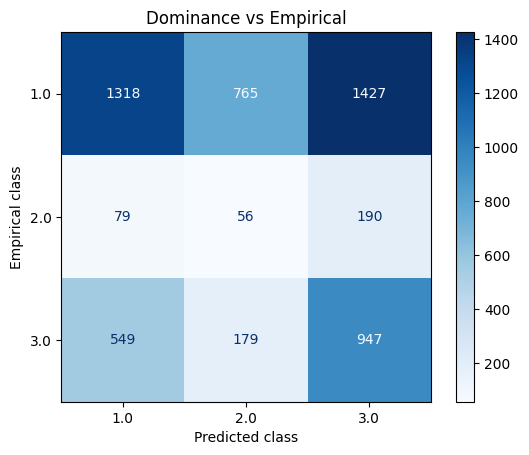


--- Dominance ---
N: 5510
Accuracy: 0.42123411978221414
Balanced accuracy: 0.37105980071154204
F1 (macro): 0.3381565410627649
Cohen's kappa: 0.070785523380825


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

# Your columns
true_col = "SICAR_domi"
methods = ["Dominance-", "Dominance"]

# Make sure all methods use the same class labels
labels = sorted(SICAR[true_col].dropna().unique())

for method in methods:

    # Remove observations with missing empirical or predicted values
    tmp = SICAR[[true_col, method]].dropna()

    y_true = tmp[true_col]
    y_pred = tmp[method]

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Plot
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(cmap="Blues")
    plt.title(f"{method} vs Empirical")
    plt.xlabel("Predicted class")
    plt.ylabel("Empirical class")
    plt.show()

    # Accuracy statistics
    print(f"\n--- {method} ---")
    print("N:", len(tmp))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))
    print("F1 (macro):", f1_score(y_true, y_pred, average="macro"))
    print("Cohen's kappa:", cohen_kappa_score(y_true, y_pred))

In [27]:
from sklearn.metrics import cohen_kappa_score

kappa_linear = cohen_kappa_score(
    y_true, y_pred, weights="linear"
)

kappa_quadratic = cohen_kappa_score(
    y_true, y_pred, weights="quadratic"
)

print("Linear weighted kappa:", kappa_linear)
print("Quadratic weighted kappa:", kappa_quadratic)

Linear weighted kappa: 0.08694435808763357
Quadratic weighted kappa: 0.09791854582831949
